In [2]:
import pandas as pd
import numpy as np
import os
os.environ["KERAS_BACKEND"] = "tensorflow"
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import keras
from keras import layers
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam, RMSprop
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
imputer = SimpleImputer(strategy="median")
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import cross_val_score
from sklearn.metrics import make_scorer, mean_squared_error
from scikeras.wrappers import KerasRegressor
from sklearn.model_selection import GridSearchCV
from joblib import dump, load

In [3]:
files = ['050', '150', '300', '400']
def make_df():
    local = 'C:\\Users\\ymarc\\Documents\\PMG\\Dados Aceleração Nivelada AT-26\\Aceleracao_FL'

    colunas = [
        'TEMPO_SAD', 'NG', 'W', 'Zp', 'Mach', 'Va', 'Ta_C', 'CL', 'CD', 'Ta_K', 'T', 'No. OBS.'
    ]

    all_dfs = [pd.read_excel(local + file + '.xls', skiprows=1, names=colunas) for file in files]

    for i, item in enumerate(all_dfs): item['H'] = float(files[i])
    df = pd.concat(all_dfs, ignore_index=True)

    df['Z'] = 0.3048*df['Zp'] # Altitude em metros
    df['a1'] = df['Z']<=11000
    df['a2'] = df['Z']>11000

    df['Pa'] = (1013.25*(1-6.87559e-6*df['Zp'])**(5.25611))*(df['a1'])+(226.306*np.exp(157.696e-6 *(11000-df['Z'])))*(df['a2']) # Pressao em mbar
    df['Rho'] = df['Pa']/(2.869*(df['Ta_K'])) # Densidade em kg/m³

    Ta0 = 288.15
    df['theta'] = df['Ta_K']/Ta0
    df['N1_over_sqrt_theta'] = df['NG']/np.sqrt(df['theta'])

    Pa0 = 1013.25
    df['delta'] = df['Pa']/Pa0
    df['T_over_delta'] = (df['T']*4.44822)/df['delta']

    S = 19.3
    df['D'] = df['Rho']*(df['Va']*0.5144)**2*S*df['CD']/2 # Arrasto em Newtons
    df['D_over_delta'] = df['D']/df['delta']

    return df

In [4]:
def split_train_test_val(df):
    df['type'] = 'train'    
    df.loc[df['H'] == 150, 'type'] = 'test'

    test_size = 0.2
    m = round((1-test_size)*len(df.loc[df['type'] == 'test']))
    val_indices = df.loc[df['type'] == 'test'].sample(n=m, random_state=42).index
    df.loc[val_indices, 'type'] = 'val'
    
    return df

In [5]:
def scale_data(df, features, targets):
    for param in features + targets:
        df[param + '_scaled'] = None

    scaler_x = MinMaxScaler()
    scaler_y = MinMaxScaler()

    for param in features:
        df.loc[df['type'] == 'train', param + '_scaled'] = scaler_x.fit_transform(df.loc[df['type'] == 'train'][[param]]).ravel()
        df.loc[df['type'] == 'test', param + '_scaled'] = scaler_x.transform(df.loc[df['type'] == 'test'][[param]]).ravel()
        df.loc[df['type'] == 'val', param + '_scaled'] = scaler_x.transform(df.loc[df['type'] == 'val'][[param]]).ravel()

    for param in targets:
        df.loc[df['type'] == 'train', param + '_scaled'] = scaler_y.fit_transform(df.loc[df['type'] == 'train'][[param]]).ravel()
        df.loc[df['type'] == 'test', param + '_scaled'] = scaler_y.transform(df.loc[df['type'] == 'test'][[param]]).ravel()
        df.loc[df['type'] == 'val', param + '_scaled'] = scaler_y.transform(df.loc[df['type'] == 'val'][[param]]).ravel()

    return df, scaler_x, scaler_y

In [6]:
def build_model(features, targets, architecture, hyperparameters):
    input_shape = (len(features), )

    model = keras.Sequential()

    targets_names = targets[0]
    for i in range(1, len(targets)):
        targets_names += '_' + targets[i]

    # Camadas ocultas
    for i in range(architecture['camadas_ocultas']):
        model.add(layers.Dense(
            architecture['neurons'], 
            input_shape=input_shape if i == 0 else None,
            activation=architecture['activation'],
            name=f'oculta_{i+1}_{targets_names}'
        ))
        
        if architecture['dropout'] > 0:
            model.add(layers.Dropout(architecture['dropout']))
    
    # Camada de saída
    model.add(layers.Dense(len(targets), name=f'saida_{targets_names}'))
    
    # Compilar modelo
    if hyperparameters['optimizer'] == 'adam':
        opt = Adam(learning_rate=hyperparameters['learning_rate'])
    else:
        opt = RMSprop(learning_rate=hyperparameters['learning_rate'])
    
    model.compile(loss="mae", optimizer=opt, metrics=["mae"])
    
    return model

In [7]:
def train_model(df, features, targets, model, hyperparameters):

    features_scaled = []
    for item in features:
        features_scaled.append(item + '_scaled')
    
    targets_scaled = []
    for item in targets:
        targets_scaled.append(item + '_scaled')

    X_train, X_val = np.array(df.loc[df['type'] == 'train', features_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', features_scaled]).astype(np.float32)
    Y_train, Y_val = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32), np.array(df.loc[df['type'] == 'val', targets_scaled]).astype(np.float32)

    callback = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=hyperparameters['patience']
    )

    training_history = model.fit(
        X_train, Y_train,
        epochs=hyperparameters['epochs'],
        batch_size=hyperparameters['batch_size'],
        callbacks=[callback],
        validation_data=(X_val, Y_val),
        verbose=0
        
    )

    return model, training_history

In [8]:
def pipeline(architecture, hyperparameters, features, targets):
    df = make_df()
    df = split_train_test_val(df)
    df, scaler_x, scaler_y = scale_data(df, features, targets)

    model = build_model(features, targets, architecture, hyperparameters)

    model, training_history = train_model(df, features, targets, model, hyperparameters)
    # training_history = 'mock'
    return df, scaler_x, scaler_y, model, training_history

In [9]:
def evaluate(model, df, features, targets, scaler_y):

    features_scaled = []
    for item in features:
        features_scaled.append(item + '_scaled')
    
    X_test = np.array(df.loc[df['type'] == 'test', features_scaled]).astype(np.float32)
    
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)

    for item in targets:
        df[item + '_pred'] = None

    for i, item in enumerate(targets):
        df.loc[df['type'] == 'test', item + '_pred'] = pred[:, i]

    real = np.array(df.loc[df['type'] == 'test', targets]).astype(np.float32)

    erro = (pred - real)* 100 / real
    avg_error = np.array([np.mean(erro[:,i]) for i in range(np.shape(erro)[1])]).astype(np.float32)

    results = {
        'predicted': pred,
        'real': real,
        'rel_error': erro,
        'avg_error': avg_error
    }
    
    return results

In [10]:
def analyze (features,
             targets,
             architecture={
                 'neurons': 60,
                 'camadas_ocultas': 2,
                 'activation': 'relu',
                 'dropout': 0.0
             },
             hyperparameters={
                 'optimizer': 'adam',
                 'learning_rate': 0.0001,
                 'epochs': 60,
                 'batch_size': 32,
                 'patience': 3
             }
            ):
    df, scaler_x, scaler_y, model, training_history = pipeline(
        architecture=architecture,
        hyperparameters=hyperparameters,
        features=features,
        targets=targets
    )

    targets_names = targets[0]
    for i in range(1, len(targets)):
        targets_names += '_' + targets[i]

    results = evaluate(model, df, features, targets, scaler_y)

    plt.plot(training_history.history['loss'])
    plt.plot(training_history.history['val_loss'])
    plt.title('Model Loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.grid()
    plt.savefig(f'{targets_names}_approach_training.png')
    plt.show()

    _, axs = plt.subplots(
        2 * len(targets),
        1,
        sharex=True,
        figsize=(12, 3 * len(targets)),
        constrained_layout=True
    )
    axs = axs.flatten()
    dot_size = 2

    for i, item in enumerate(targets):
        axs[2*i].set_title(f'Actual vs. Predicted {item}')
        axs[2*i].scatter(df.loc[df['type'] == 'test']['No. OBS.'], df.loc[df['type']=='test'][f'{item}'], dot_size, label=f'Predicted {item}')
        axs[2*i].scatter(df.loc[df['type'] == 'test']['No. OBS.'], df.loc[df['type']=='test'][f'{item}_pred'], dot_size, label=f'Actual {item}')
        axs[2*i].legend()
        axs[2*i].grid()

        axs[2*i+1].set_title(f'Average Error: {results["avg_error"][i]:.2f}%')
        axs[2*i+1].scatter(df.loc[df['type'] == 'test']['No. OBS.'], results["rel_error"][:,i], dot_size)
        axs[2*i+1].legend()
        axs[2*i+1].grid()
    plt.savefig(f'{targets_names}_approach_results.png')
    plt.show()

    return df, scaler_x, scaler_y, model, training_history, results

### Arquitetura Original:

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 869us/step


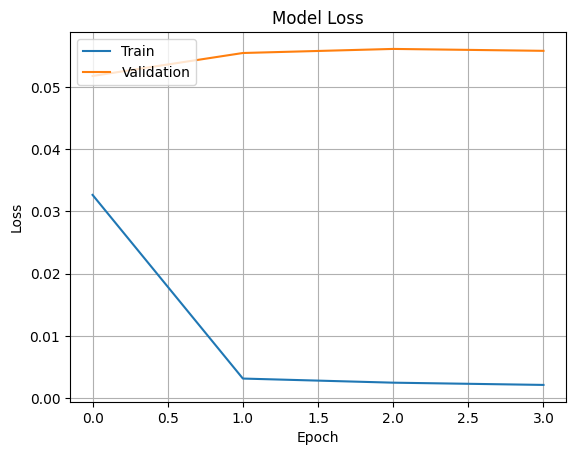

C:\Users\ymarc\AppData\Local\Temp\ipykernel_22348\2208187966.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()
C:\Users\ymarc\AppData\Local\Temp\ipykernel_22348\2208187966.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


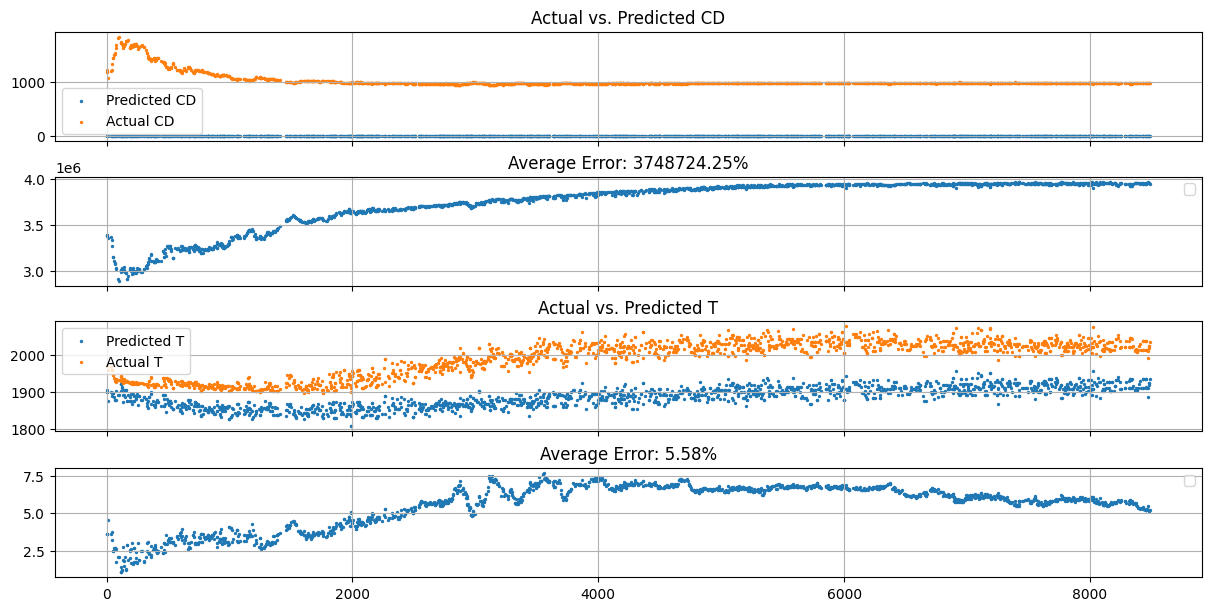

In [11]:
combined_analysis = analyze(features=['CL', 'Mach', 'NG', 'W', 'Zp', 'Ta_K'], targets=['CD', 'T'])

### Arquitetura Original + Adimensionalização:

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 879us/step


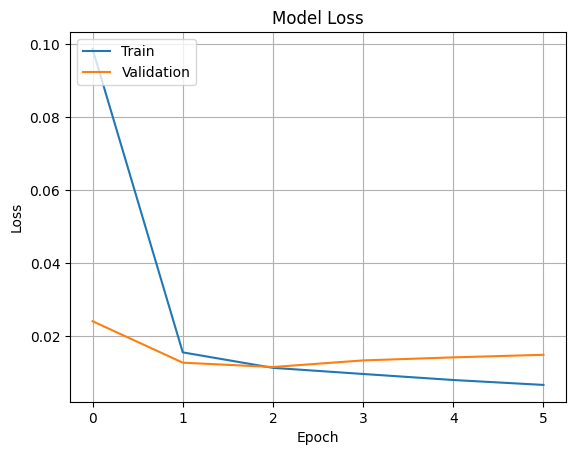

C:\Users\ymarc\AppData\Local\Temp\ipykernel_22348\2208187966.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()
C:\Users\ymarc\AppData\Local\Temp\ipykernel_22348\2208187966.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


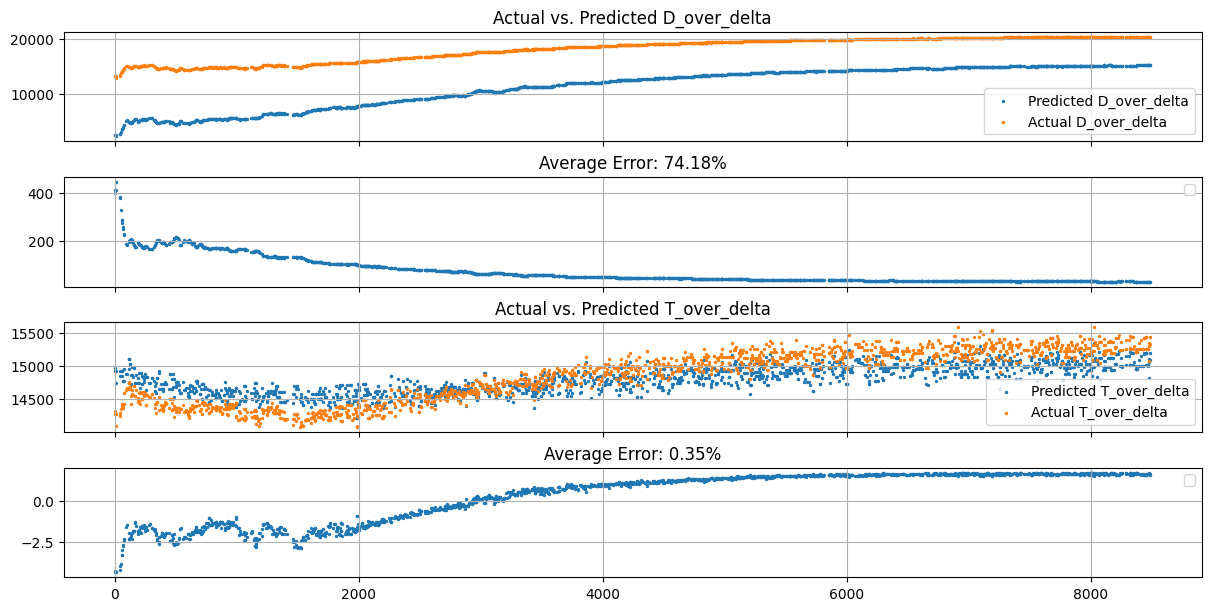

In [12]:
combined_analysis_over_delta = analyze(features=['CL', 'Mach', 'N1_over_sqrt_theta'], targets=['D_over_delta', 'T_over_delta'])

### Arquitetura Separada:

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 837us/step


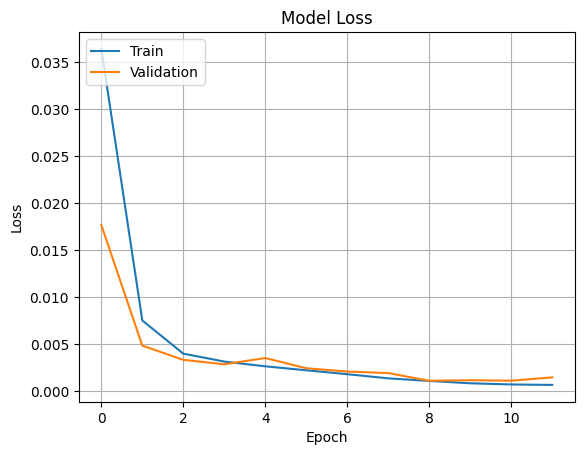

C:\Users\ymarc\AppData\Local\Temp\ipykernel_22348\2208187966.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


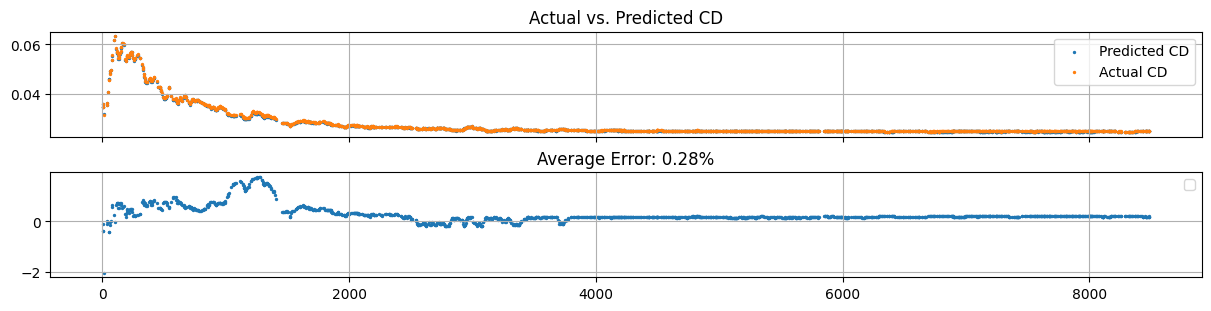

In [13]:
isolated_analysis_CD = analyze(features=['CL', 'Mach'], targets=['CD'])

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 960us/step


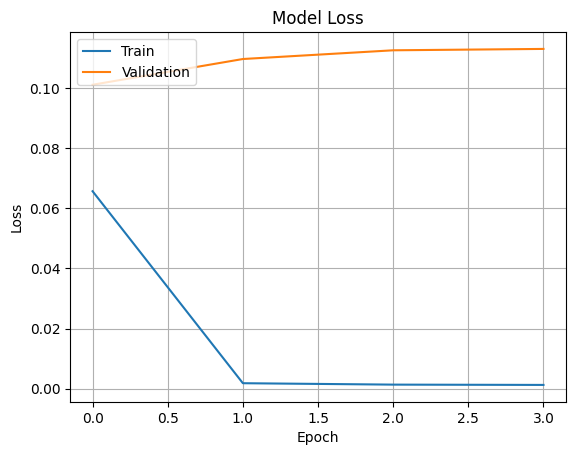

C:\Users\ymarc\AppData\Local\Temp\ipykernel_22348\2208187966.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


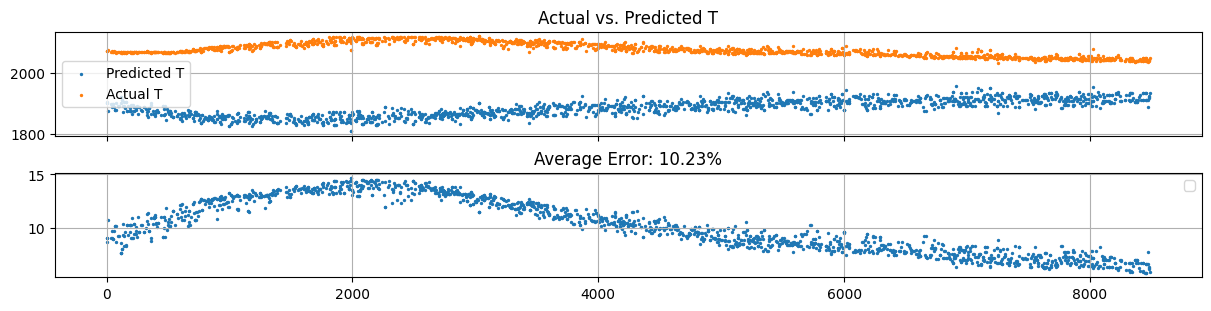

In [14]:
isolated_analysis_T = analyze(features=['Mach', 'NG', 'W', 'Zp', 'Ta_K'], targets=['T'])

### Separação + Adimensionalização:

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 848us/step


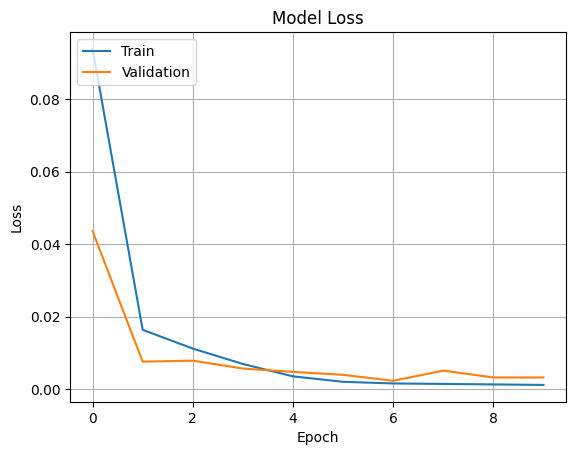

C:\Users\ymarc\AppData\Local\Temp\ipykernel_22348\2208187966.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


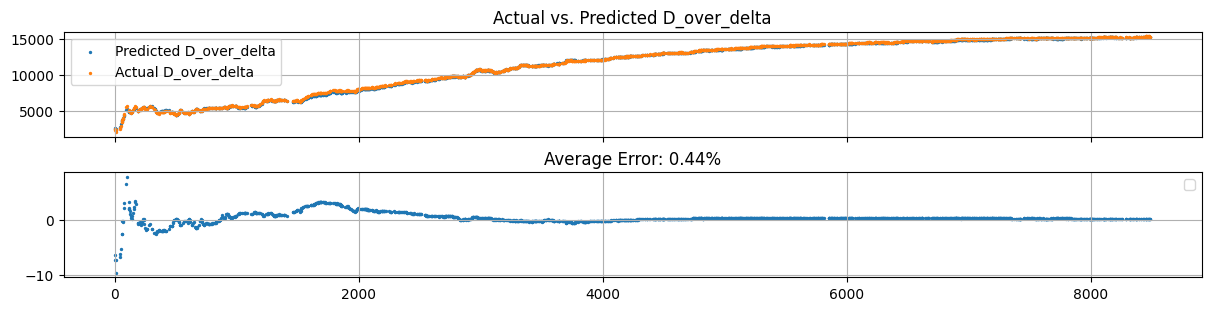

In [15]:
isolated_analysis_CD_over_delta = analyze(features=['CL', 'Mach'], targets=['D_over_delta'])

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 944us/step


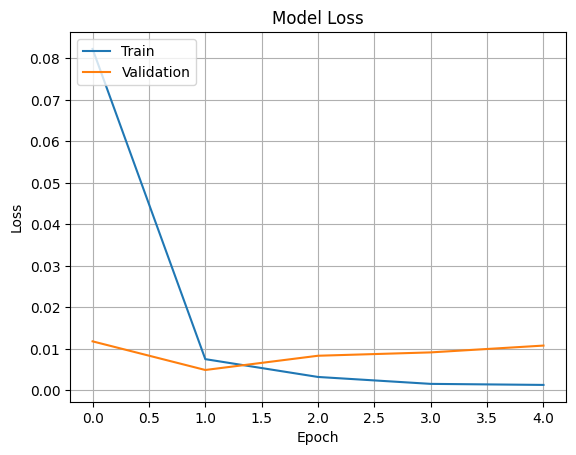

C:\Users\ymarc\AppData\Local\Temp\ipykernel_22348\2208187966.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


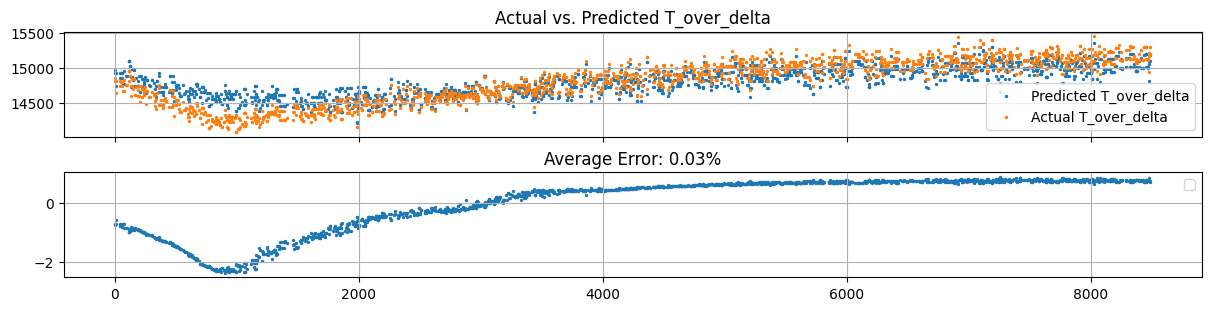

In [16]:
isolated_analysis_T_over_delta = analyze(features=['Mach', 'N1_over_sqrt_theta'], targets=['T_over_delta'])

### Grid Search:

return df, scaler_x, scaler_y, model, training_history, results

In [18]:
def model_constructor_grid_search(features, targets, neurons, optimizer, learning_rate, batch_size, epochs):
    return build_model(
        features=features,
        targets=targets,
        architecture={
            'neurons': neurons,
            'camadas_ocultas': 2,
            'activation': 'relu',
            'dropout': 0.0
        },
        hyperparameters={
            'optimizer': optimizer,
            'learning_rate': learning_rate,
            'epochs': epochs,
            'batch_size': batch_size,
            'patience': 3
        }
    )

In [39]:
approaches = {
    'combined_analysis': {
        'features': ['CL', 'Mach', 'NG', 'W', 'Zp', 'Ta_K'],
        'targets': ['CD', 'T'],
        'data': combined_analysis
    },
    'combined_analysis_over_delta': {
        'features': ['CL', 'Mach', 'N1_over_sqrt_theta'],
        'targets': ['D_over_delta', 'T_over_delta'],
        'data': combined_analysis_over_delta
    },
    'isolated_analysis_CD': {
        'features': ['CL', 'Mach'],
        'targets': ['CD'],
        'data': isolated_analysis_CD
    },
    'isolated_analysis_T': {
        'features': ['Mach', 'NG', 'W', 'Zp', 'Ta_K'],
        'targets': ['T'],
        'data': isolated_analysis_T
    },
    'isolated_analysis_CD_over_delta': {
        'features': ['CL', 'Mach'],
        'targets': ['D_over_delta'],
        'data': isolated_analysis_CD_over_delta
    },
    'isolated_analysis_T_over_delta': {
        'features': ['Mach', 'N1_over_sqrt_theta'],
        'targets': ['T_over_delta'],
        'data': isolated_analysis_T_over_delta
    }
}

grid_results = []
for approach in approaches:
    print('approach:', approach)

    features = approaches[approach]['features']
    targets = approaches[approach]['targets']

    features_scaled = []
    for item in features:
        features_scaled.append(item + '_scaled')
    targets_scaled = []
    for item in targets:
        targets_scaled.append(item + '_scaled')

    param_grid = {
        'model__neurons': [30, 40, 60],
        'model__optimizer': ['adam'],
        'model__learning_rate': [0.001, 0.0001, 0.00001],
        'model__batch_size': [16, 32, 64],
        'model__epochs': [60, 80, 100]
    }

    # param_grid = {
    #     'model__neurons': [30],
    #     'model__optimizer': ['adam'],
    #     'model__learning_rate': [0.001],
    #     'model__batch_size': [16],
    #     'model__epochs': [60] # Reduzi para 1 valor para o exemplo rodar mais rápido
    # }

    model_wrapper = KerasRegressor(model=model_constructor_grid_search, features=features_scaled, targets=targets_scaled, verbose=1)

    grid = GridSearchCV(model_wrapper, param_grid=param_grid, scoring='neg_mean_absolute_error', cv=3, n_jobs=-1)

    df = approaches[approach]['data'][0]
    X_train_s = np.array(df.loc[df['type'] == 'train', features_scaled]).astype(np.float32)
    Y_train_s = np.array(df.loc[df['type'] == 'train', targets_scaled]).astype(np.float32)

    grid_result = grid.fit(X_train_s, Y_train_s)

    grid_results.append(grid_result)

approach: combined_analysis


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 1s 739us/step - loss: 0.0155 - mae: 0.0155
approach: combined_analysis_over_delta


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 1s 814us/step - loss: 0.0309 - mae: 0.0309
approach: isolated_analysis_CD


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


... (3 outputs left out)

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 1s 719us/step - loss: 0.0233 - mae: 0.0233
approach: isolated_analysis_T_over_delta


c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


1063/1063 ━━━━━━━━━━━━━━━━━━━━ 1s 738us/step - loss: 0.0159 - mae: 0.0159


Executar novamente, com mais parâmetros, e ativando o callback (talvez implementar outra maneira de callback)

In [43]:
for result in grid_results:    
    # Exibe a melhor combinação de parâmetros encontrada
    print("Melhores Parâmetros:")
    print(result.best_params_)

    # Exibe o melhor score (Erro Absoluto Médio Negativo)
    best_score_negativo = result.best_score_
    print(f"Melhor Score (MAE Negativo): {best_score_negativo:.4f}")

    # Converte para o MAE real para melhor interpretação
    melhor_mae = -best_score_negativo
    print(f"Isso equivale a um Erro Absoluto Médio (MAE) de: {melhor_mae:.4f}")

Melhores Parâmetros:
{'model__batch_size': 64, 'model__epochs': 100, 'model__learning_rate': 0.001, 'model__neurons': 40, 'model__optimizer': 'adam'}
Melhor Score (MAE Negativo): -0.0840
Isso equivale a um Erro Absoluto Médio (MAE) de: 0.0840
Melhores Parâmetros:
{'model__batch_size': 32, 'model__epochs': 80, 'model__learning_rate': 0.001, 'model__neurons': 40, 'model__optimizer': 'adam'}
Melhor Score (MAE Negativo): -0.0435
Isso equivale a um Erro Absoluto Médio (MAE) de: 0.0435
Melhores Parâmetros:
{'model__batch_size': 64, 'model__epochs': 80, 'model__learning_rate': 0.001, 'model__neurons': 40, 'model__optimizer': 'adam'}
Melhor Score (MAE Negativo): -0.0166
Isso equivale a um Erro Absoluto Médio (MAE) de: 0.0166
Melhores Parâmetros:
{'model__batch_size': 32, 'model__epochs': 80, 'model__learning_rate': 0.0001, 'model__neurons': 60, 'model__optimizer': 'adam'}
Melhor Score (MAE Negativo): -0.0858
Isso equivale a um Erro Absoluto Médio (MAE) de: 0.0858
Melhores Parâmetros:
{'model__

### Arquitetura Original:

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 989us/step


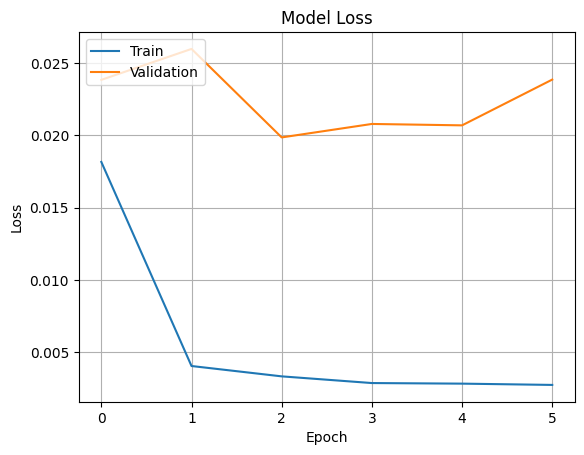

C:\Users\ymarc\AppData\Local\Temp\ipykernel_56484\2805155737.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()
C:\Users\ymarc\AppData\Local\Temp\ipykernel_56484\2805155737.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


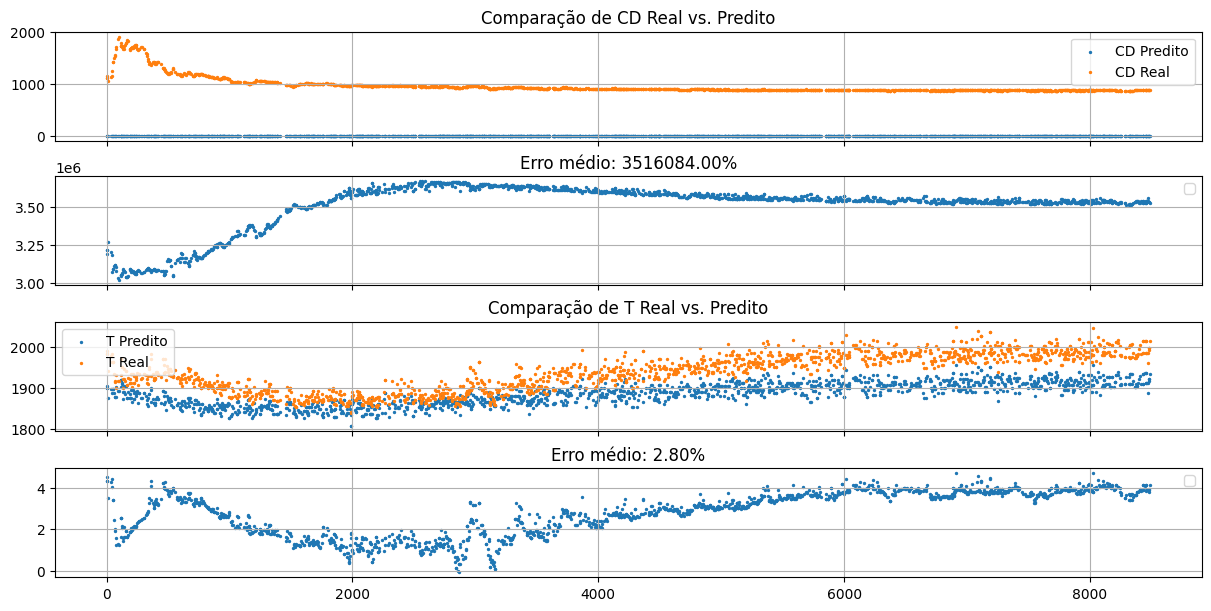

In [44]:
combined_analysis = analyze(features=['CL', 'Mach', 'NG', 'W', 'Zp', 'Ta_K'], targets=['CD', 'T'],
                            architecture={
                                'neurons': 40,
                                'camadas_ocultas': 2,
                                'activation': 'relu',
                                'dropout': 0.0
                            },
                            hyperparameters={
                                'optimizer': 'adam',
                                'learning_rate': 0.001,
                                'epochs': 100,
                                'batch_size': 64,
                                'patience': 3
                            })

### Arquitetura Original + Adimensionalização:

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 839us/step


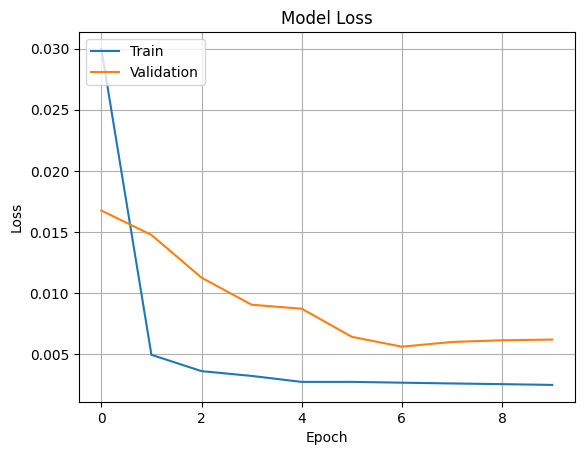

C:\Users\ymarc\AppData\Local\Temp\ipykernel_56484\2805155737.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()
C:\Users\ymarc\AppData\Local\Temp\ipykernel_56484\2805155737.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


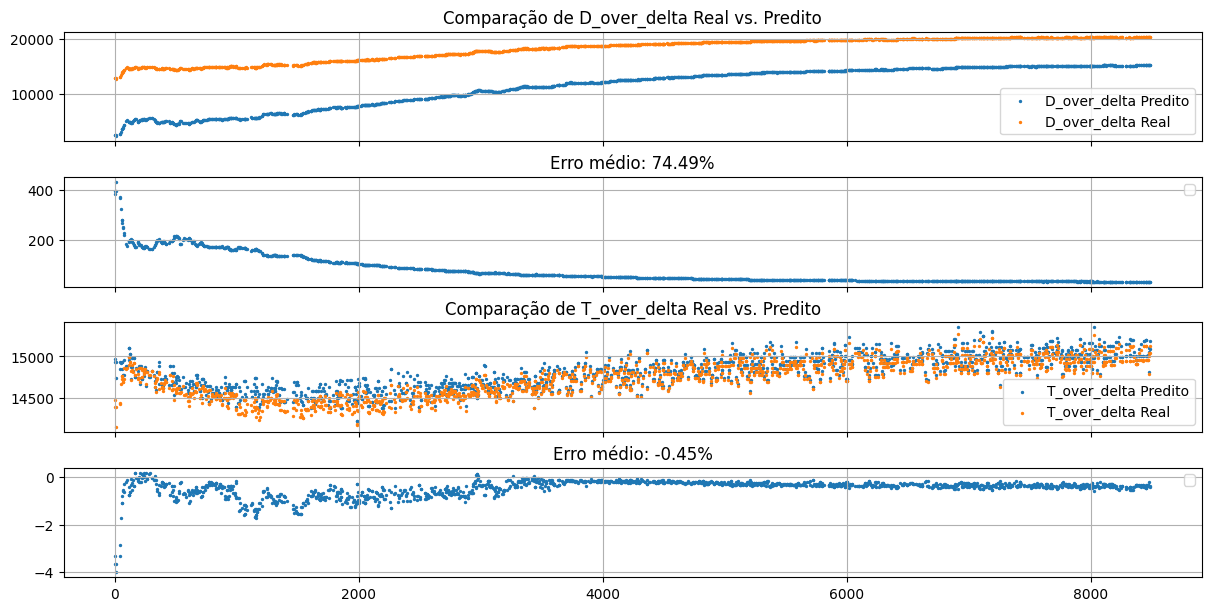

In [45]:
combined_analysis_over_delta = analyze(features=['CL', 'Mach', 'N1_over_sqrt_theta'], targets=['D_over_delta', 'T_over_delta'],
                                       architecture={
                                            'neurons': 40,
                                            'camadas_ocultas': 2,
                                            'activation': 'relu',
                                            'dropout': 0.0
                                        },
                                        hyperparameters={
                                            'optimizer': 'adam',
                                            'learning_rate': 0.001,
                                            'epochs': 80,
                                            'batch_size': 32,
                                            'patience': 3
                                        })

### Arquitetura Separada:

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 874us/step


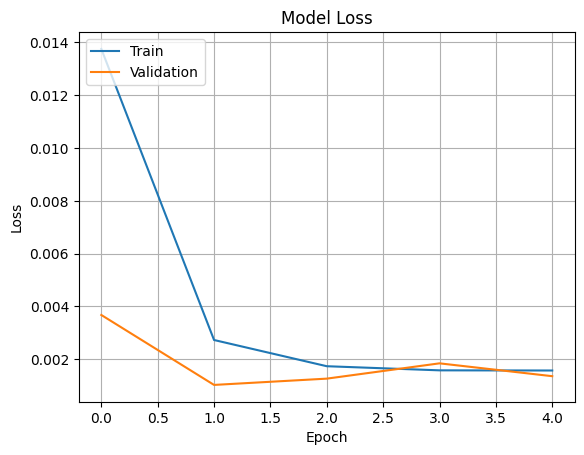

C:\Users\ymarc\AppData\Local\Temp\ipykernel_56484\2805155737.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


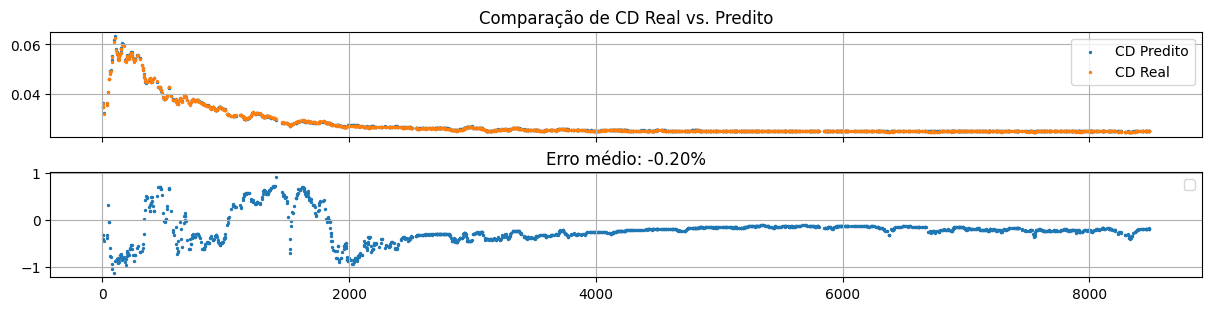

In [46]:
isolated_analysis_CD = analyze(features=['CL', 'Mach'], targets=['CD'],
                               architecture={
                                    'neurons': 40,
                                    'camadas_ocultas': 2,
                                    'activation': 'relu',
                                    'dropout': 0.0
                                },
                                hyperparameters={
                                    'optimizer': 'adam',
                                    'learning_rate': 0.001,
                                    'epochs': 80,
                                    'batch_size': 64,
                                    'patience': 3
                                })

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 711us/step


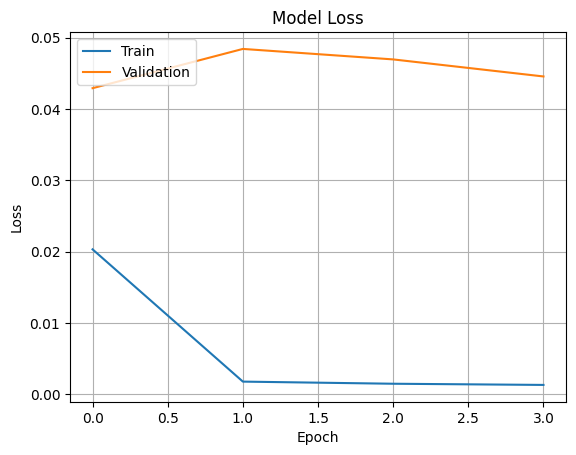

C:\Users\ymarc\AppData\Local\Temp\ipykernel_56484\2805155737.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


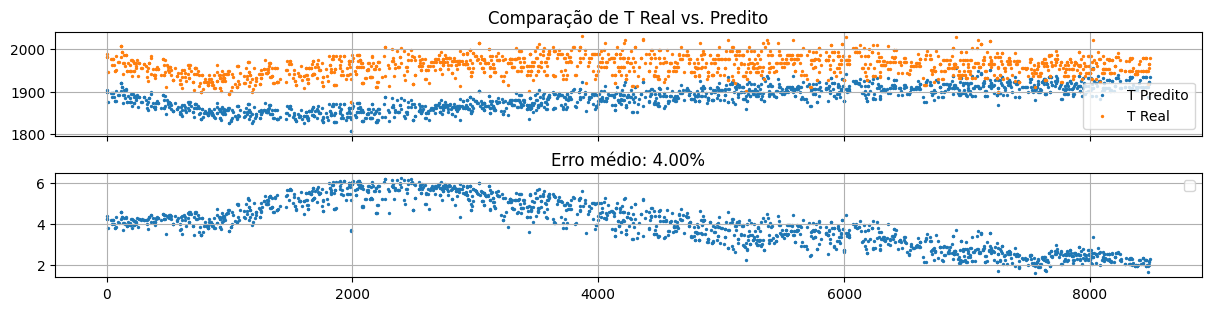

In [47]:
isolated_analysis_T = analyze(features=['Mach', 'NG', 'W', 'Zp', 'Ta_K'], targets=['T'],
                               architecture={
                                    'neurons': 60,
                                    'camadas_ocultas': 2,
                                    'activation': 'relu',
                                    'dropout': 0.0
                                },
                                hyperparameters={
                                    'optimizer': 'adam',
                                    'learning_rate': 0.0001,
                                    'epochs': 80,
                                    'batch_size': 32,
                                    'patience': 3
                                })

### Separação + Adimensionalização:

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 597us/step


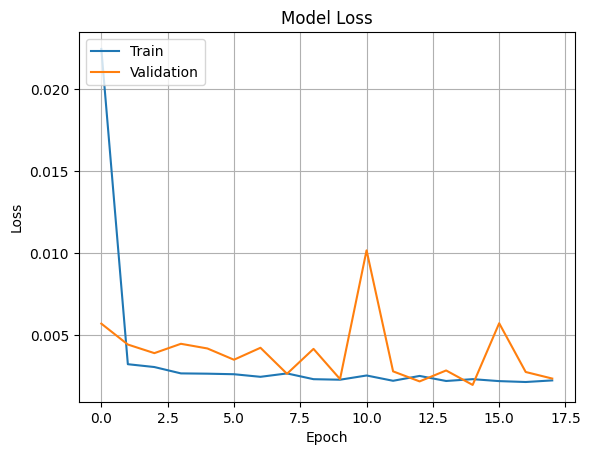

C:\Users\ymarc\AppData\Local\Temp\ipykernel_56484\2805155737.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


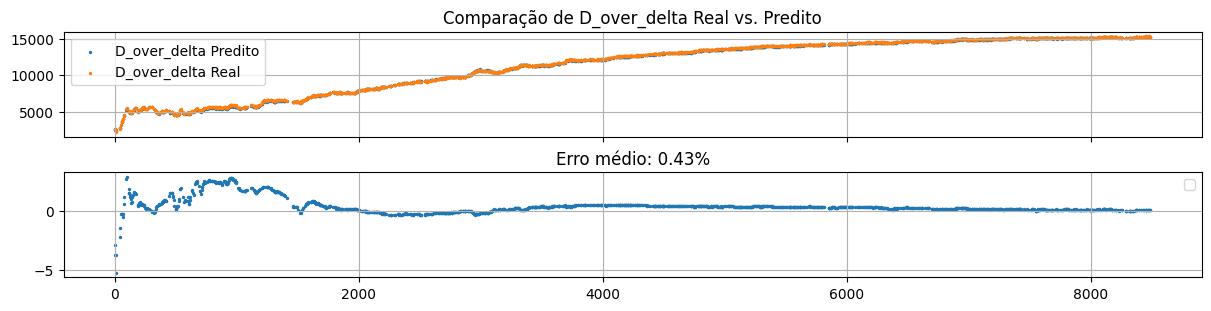

In [48]:
isolated_analysis_CD_over_delta = analyze(features=['CL', 'Mach'], targets=['D_over_delta'],
                                          architecture={
                                    'neurons': 60,
                                    'camadas_ocultas': 2,
                                    'activation': 'relu',
                                    'dropout': 0.0
                                },
                                hyperparameters={
                                    'optimizer': 'adam',
                                    'learning_rate': 0.001,
                                    'epochs': 80,
                                    'batch_size': 32,
                                    'patience': 3
                                })

c:\Users\ymarc\Documents\PMG\venv\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


54/54 ━━━━━━━━━━━━━━━━━━━━ 0s 790us/step


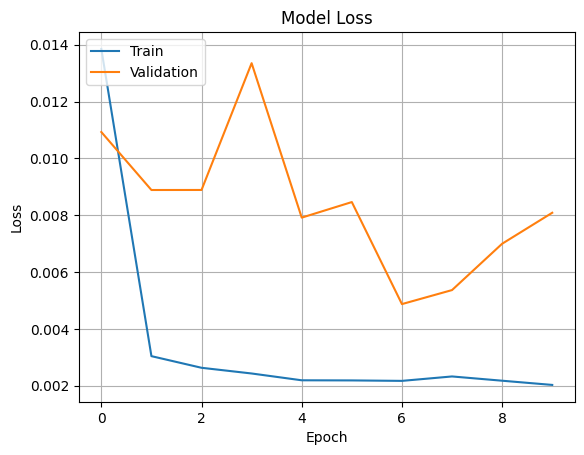

C:\Users\ymarc\AppData\Local\Temp\ipykernel_56484\2805155737.py:59: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2*i+1].legend()


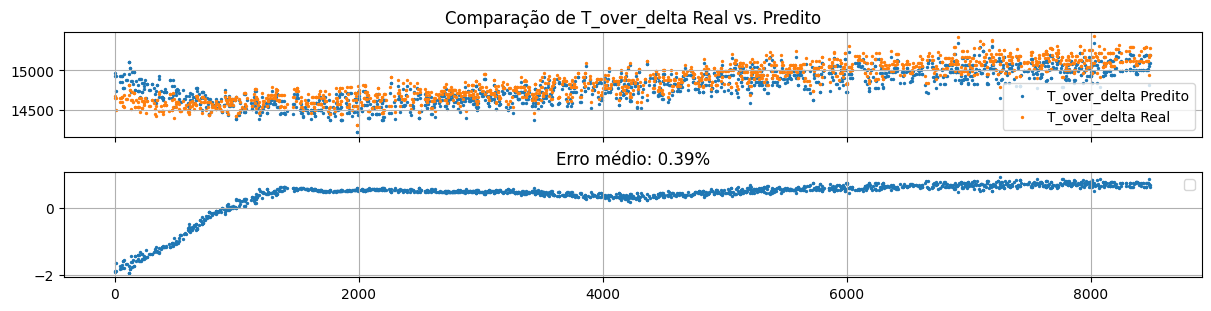

In [49]:
isolated_analysis_T_over_delta = analyze(features=['Mach', 'N1_over_sqrt_theta'], targets=['T_over_delta'],
                                          architecture={
                                    'neurons': 40,
                                    'camadas_ocultas': 2,
                                    'activation': 'relu',
                                    'dropout': 0.0
                                },
                                hyperparameters={
                                    'optimizer': 'adam',
                                    'learning_rate': 0.001,
                                    'epochs': 80,
                                    'batch_size': 16,
                                    'patience': 3
                                })